In [1]:
# E-Commerce Sales Data Analysis
# Fundamentals of Machine Learning

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("All Libraries Imported Successfully!")


All Libraries Imported Successfully!


In [2]:
# STEP 3: Create E-Commerce Sales Dataset

import pandas as pd
import numpy as np

np.random.seed(42)

# Generate 1000 sales records
dates = pd.date_range(start="2024-01-01", end="2025-12-31")

products = ["Laptop", "Mobile", "Headphones",
            "Keyboard", "Mouse", "Smartwatch"]

categories = {
    "Laptop": "Electronics",
    "Mobile": "Electronics",
    "Headphones": "Accessories",
    "Keyboard": "Accessories",
    "Mouse": "Accessories",
    "Smartwatch": "Electronics"
}

prices = {
    "Laptop": 50000,
    "Mobile": 20000,
    "Headphones": 1500,
    "Keyboard": 1000,
    "Mouse": 500,
    "Smartwatch": 3000
}

data = []

for i in range(1000):
    product = np.random.choice(products)
    quantity = np.random.randint(1, 6)
    price = prices[product]

    data.append([
        i + 1,
        np.random.choice(dates),
        product,
        categories[product],
        quantity,
        price,
        quantity * price
    ])

df = pd.DataFrame(data, columns=[
    "Order_ID",
    "Order_Date",
    "Product",
    "Category",
    "Quantity",
    "Price",
    "Total_Sales"
])

# Save dataset
df.to_csv("ecommerce_sales.csv", index=False)

print("Dataset Created Successfully!")

display(df.head(10))

Dataset Created Successfully!


,Order_ID,Order_Date,Product,Category,Quantity,Price,Total_Sales
0,1,2024-09-27,Keyboard,Accessories,5,1000,5000
1,2,2024-01-21,Headphones,Accessories,5,1500,7500
2,3,2024-08-02,Mobile,Electronics,3,20000,60000
3,4,2024-03-28,Headphones,Accessories,3,1500,4500
4,5,2025-10-25,Mouse,Accessories,4,500,2000
5,6,2024-12-09,Headphones,Accessories,5,1500,7500
6,7,2024-07-10,Keyboard,Accessories,2,1000,2000
7,8,2024-06-09,Keyboard,Accessories,5,1000,5000
8,9,2024-01-22,Keyboard,Accessories,2,1000,2000
9,10,2025-07-14,Mouse,Accessories,4,500,2000


In [3]:
# STEP 4: Data Cleaning and Preprocessing

# 1. Check dataset information
print("Dataset Information:")
df.info()

# 2. Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# 3. Check duplicate records
print("\nDuplicate Records:")
print(df.duplicated().sum())

# 4. Remove duplicate records
df = df.drop_duplicates()

# 5. Handle missing values
df = df.dropna()

# 6. Convert Order_Date to datetime
df["Order_Date"] = pd.to_datetime(df["Order_Date"])

# 7. Extract Month and Year
df["Month"] = df["Order_Date"].dt.month
df["Year"] = df["Order_Date"].dt.year

# 8. Display cleaned dataset
print("\nCleaned Dataset:")
display(df.head(10))

print("\nData Cleaning Completed Successfully!")


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   Order_ID     1000 non-null   int64         
 1   Order_Date   1000 non-null   datetime64[ns]
 2   Product      1000 non-null   object        
 3   Category     1000 non-null   object        
 4   Quantity     1000 non-null   int64         
 5   Price        1000 non-null   int64         
 6   Total_Sales  1000 non-null   int64         
dtypes: datetime64[ns](1), int64(4), object(2)
memory usage: 54.8+ KB

Missing Values:
Order_ID       0
Order_Date     0
Product        0
Category       0
Quantity       0
Price          0
Total_Sales    0
dtype: int64

Duplicate Records:
0

Cleaned Dataset:


,Order_ID,Order_Date,Product,Category,Quantity,Price,Total_Sales,Month,Year
0,1,2024-09-27,Keyboard,Accessories,5,1000,5000,9,2024
1,2,2024-01-21,Headphones,Accessories,5,1500,7500,1,2024
2,3,2024-08-02,Mobile,Electronics,3,20000,60000,8,2024
3,4,2024-03-28,Headphones,Accessories,3,1500,4500,3,2024
4,5,2025-10-25,Mouse,Accessories,4,500,2000,10,2025
5,6,2024-12-09,Headphones,Accessories,5,1500,7500,12,2024
6,7,2024-07-10,Keyboard,Accessories,2,1000,2000,7,2024
7,8,2024-06-09,Keyboard,Accessories,5,1000,5000,6,2024
8,9,2024-01-22,Keyboard,Accessories,2,1000,2000,1,2024
9,10,2025-07-14,Mouse,Accessories,4,500,2000,7,2025



Data Cleaning Completed Successfully!


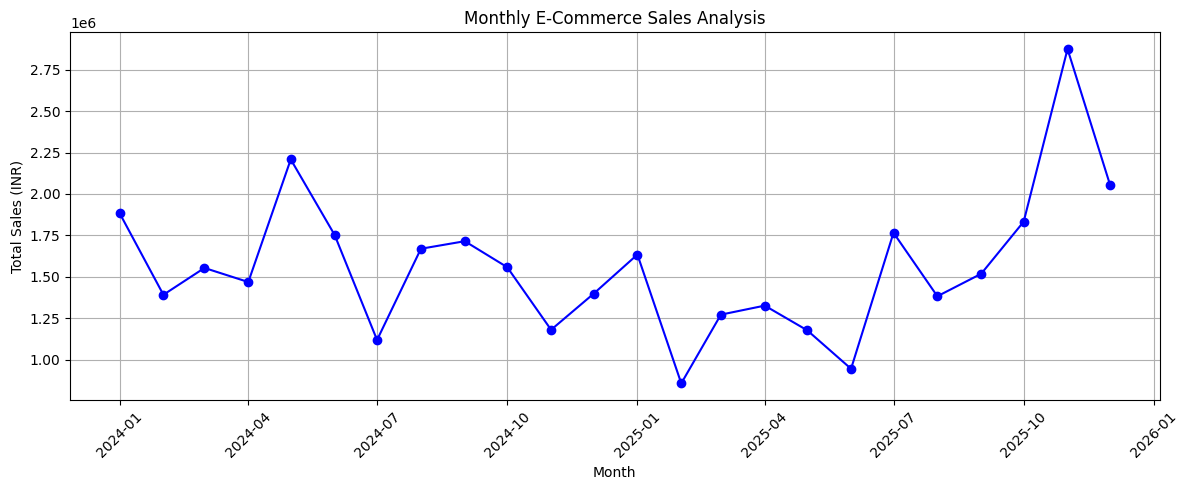

In [5]:
# Monthly Sales Analysis

monthly_sales = df.groupby(
    ["Year", "Month"]
)["Total_Sales"].sum().reset_index()

monthly_sales["Date"] = pd.to_datetime(
    monthly_sales[["Year", "Month"]].assign(DAY=1)
)

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales["Date"],
    monthly_sales["Total_Sales"],
    marker="o",
    color="blue"
)

plt.title("Monthly E-Commerce Sales Analysis")
plt.xlabel("Month")
plt.ylabel("Total Sales (INR)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

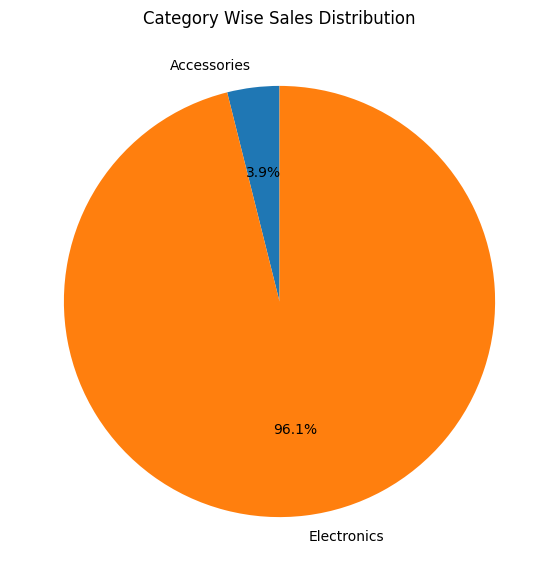

In [6]:
# Category Wise Sales Analysis

category_sales = df.groupby(
    "Category"
)["Total_Sales"].sum()

plt.figure(figsize=(7, 7))

plt.pie(
    category_sales,
    labels=category_sales.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Category Wise Sales Distribution")
plt.show()

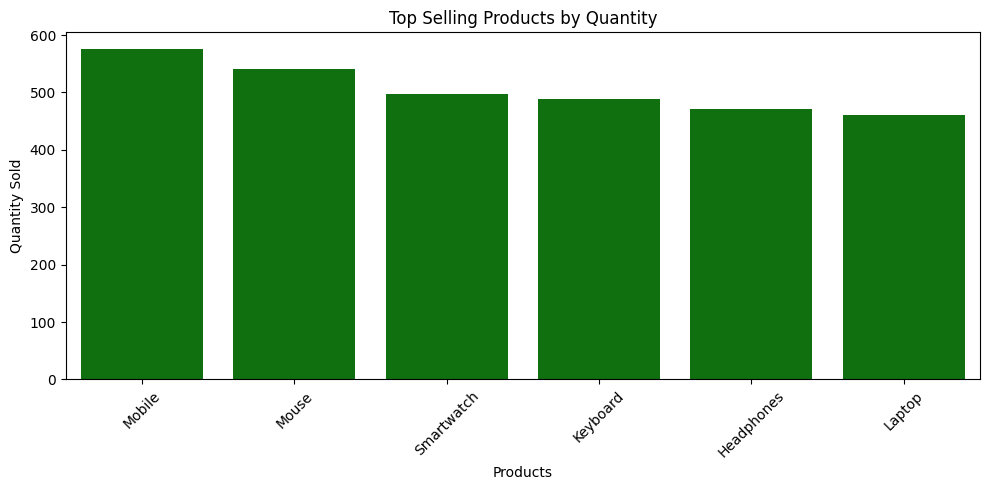

In [7]:
# Top Selling Products by Quantity

quantity_sales = df.groupby(
    "Product"
)["Quantity"].sum().sort_values(ascending=False)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=quantity_sales.index,
    y=quantity_sales.values,
    color="green"
)

plt.title("Top Selling Products by Quantity")
plt.xlabel("Products")
plt.ylabel("Quantity Sold")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [8]:
# STEP 6.1: Prepare Data for Machine Learning

# Sort monthly sales by date
monthly_sales = monthly_sales.sort_values("Date").copy()

# Create a numerical time feature
monthly_sales["Month_Index"] = np.arange(
    len(monthly_sales)
)

# Input feature
X = monthly_sales[["Month_Index"]]

# Target variable
y = monthly_sales["Total_Sales"]

print("Machine Learning Dataset:")
display(monthly_sales.head(10))


Machine Learning Dataset:


,Year,Month,Total_Sales,Date,Month_Index
0,2024,1,1884500,2024-01-01,0
1,2024,2,1391000,2024-02-01,1
2,2024,3,1553000,2024-03-01,2
3,2024,4,1468000,2024-04-01,3
4,2024,5,2208500,2024-05-01,4
5,2024,6,1752500,2024-06-01,5
6,2024,7,1118000,2024-07-01,6
7,2024,8,1669000,2024-08-01,7
8,2024,9,1714500,2024-09-01,8
9,2024,10,1557500,2024-10-01,9


In [9]:
# STEP 6.2: Train-Test Split

# Use earlier months for training
# and later months for testing

split_index = int(len(monthly_sales) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

Training Records: 19
Testing Records: 5


In [10]:
# STEP 6.3: Train Machine Learning Model

model = LinearRegression()

model.fit(X_train, y_train)

print("Linear Regression Model Trained Successfully!")

Linear Regression Model Trained Successfully!


In [11]:
# STEP 6.4: Sales Prediction

y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Actual_Sales": y_test.values,
    "Predicted_Sales": y_pred
})

print("Actual vs Predicted Sales:")
display(results)

Actual vs Predicted Sales:


,Actual_Sales,Predicted_Sales
0,1382000,1.186921e+06
1,1518000,1.158953e+06
2,1832500,1.130984e+06
3,2875000,1.103016e+06
4,2056000,1.075047e+06


In [12]:
# STEP 6.5: Model Evaluation

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("========== MODEL PERFORMANCE ==========")

print("Mean Absolute Error:", round(mae, 2))
print("Mean Squared Error:", round(mse, 2))
print("Root Mean Squared Error:", round(rmse, 2))
print("R2 Score:", round(r2, 4))

========== MODEL PERFORMANCE ==========
Mean Absolute Error: 801715.79
Mean Squared Error: 952258263822.71
Root Mean Squared Error: 975837.21
R2 Score: -2.4293


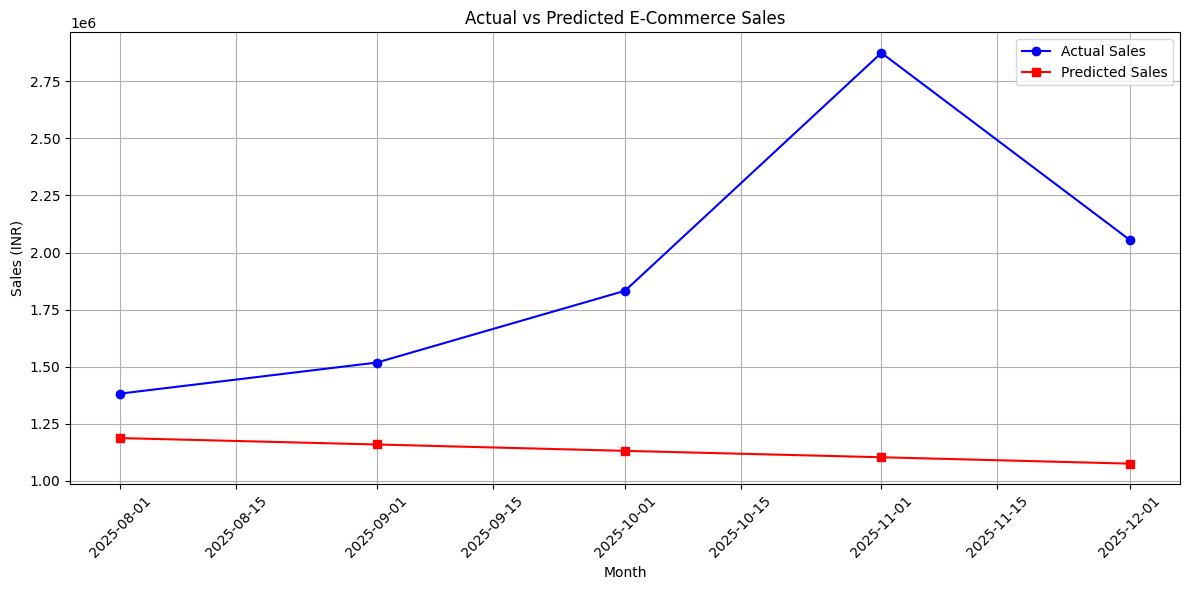

In [13]:
# Actual vs Predicted Sales Visualization

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_sales["Date"].iloc[split_index:],
    y_test,
    marker="o",
    label="Actual Sales",
    color="blue"
)

plt.plot(
    monthly_sales["Date"].iloc[split_index:],
    y_pred,
    marker="s",
    label="Predicted Sales",
    color="red"
)

plt.title("Actual vs Predicted E-Commerce Sales")
plt.xlabel("Month")
plt.ylabel("Sales (INR)")

plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [16]:
# STEP 7: Future Sales Prediction

# Retrain the model using all 24 months
# after completing test evaluation
final_model = LinearRegression()
final_model.fit(X, y)

# Generate next 6 months
future_dates = pd.date_range(
    start=monthly_sales["Date"].max() + pd.DateOffset(months=1),
    periods=6,
    freq="MS"
)

# Create future month indices
future_indices = pd.DataFrame({
    "Month_Index": np.arange(
        len(monthly_sales),
        len(monthly_sales) + 6
    )
})

# Predict future sales
future_predictions = final_model.predict(future_indices)

# Create prediction table
future_df = pd.DataFrame({
    "Month": future_dates.strftime("%B %Y"),
    "Predicted_Sales": future_predictions.round(2)
})

print("========== FUTURE SALES PREDICTION ==========")
display(future_df)

========== FUTURE SALES PREDICTION ==========


,Month,Predicted_Sales
0,January 2026,1660474.64
1,February 2026,1668215.94
2,March 2026,1675957.25
3,April 2026,1683698.55
4,May 2026,1691439.86
5,June 2026,1699181.16


In [17]:
# STEP 7: Future Sales Prediction

# Retrain the model using all 24 months
# after completing test evaluation
final_model = LinearRegression()
final_model.fit(X, y)

# Generate next 6 months
future_dates = pd.date_range(
    start=monthly_sales["Date"].max() + pd.DateOffset(months=1),
    periods=6,
    freq="MS"
)

# Create future month indices
future_indices = pd.DataFrame({
    "Month_Index": np.arange(
        len(monthly_sales),
        len(monthly_sales) + 6
    )
})

# Predict future sales
future_predictions = final_model.predict(future_indices)

# Create prediction table
future_df = pd.DataFrame({
    "Month": future_dates.strftime("%B %Y"),
    "Predicted_Sales": future_predictions.round(2)
})

print("========== FUTURE SALES PREDICTION ==========")
display(future_df)


========== FUTURE SALES PREDICTION ==========


,Month,Predicted_Sales
0,January 2026,1660474.64
1,February 2026,1668215.94
2,March 2026,1675957.25
3,April 2026,1683698.55
4,May 2026,1691439.86
5,June 2026,1699181.16


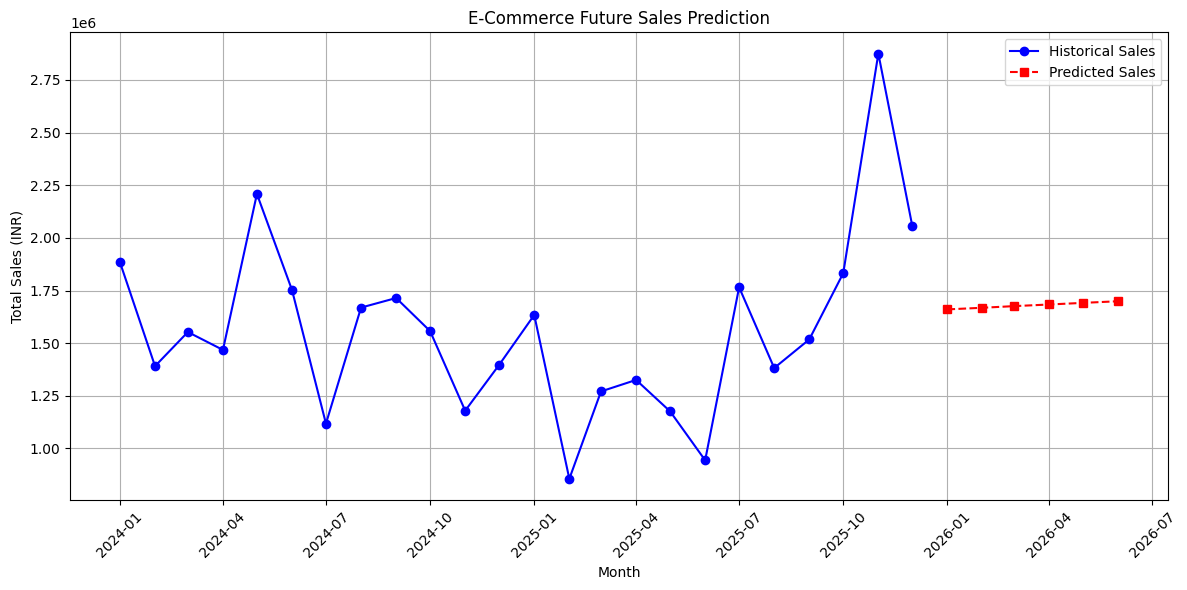

In [18]:
# Future Sales Prediction Graph

plt.figure(figsize=(12, 6))

# Historical sales
plt.plot(
    monthly_sales["Date"],
    monthly_sales["Total_Sales"],
    marker="o",
    label="Historical Sales",
    color="blue"
)

# Future predicted sales
plt.plot(
    future_dates,
    future_predictions,
    marker="s",
    linestyle="--",
    label="Predicted Sales",
    color="red"
)

plt.title("E-Commerce Future Sales Prediction")
plt.xlabel("Month")
plt.ylabel("Total Sales (INR)")

plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [19]:
# Save Future Sales Predictions

future_df.to_csv(
    "Future_Sales_Predictions.csv",
    index=False
)

print("Future Sales Predictions Saved Successfully!")

Future Sales Predictions Saved Successfully!
